# Scalability Test

In [1]:
from __future__ import annotations

import sys
from itertools import product
from pathlib import Path

import numpy as np
from sklearn.feature_selection import RFE
from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier

sys.path.insert(0, "..")
sys.path.insert(0, ".")
from scalability.funcs import Progress, rows_from_results, plot_sram, plot_tcam
from utils.baseline_converters import SYSTEMS, count_dt_resources as count_baseline
from utils.constants import DEFAULT_RANDOM_STATE, QUANTIZED_MIN, QUANTIZED_MAX
from utils.model_conversion import count_dt_resources as count_ss

DATASET_ROOT = Path("../datasets/ciciot22")
FEATURE_COUNT = 9
DEPTHS = list(range(3, 28, 2))
MAX_LEAVES = [128, 256, 512, 1024, None]
STAGE_LIMIT = 20

In [2]:
X_train, X_test = (np.load(DATASET_ROOT / f"X_{split}.npy") for split in ("train", "test"))
raw_y_train, raw_y_test = (
    np.load(DATASET_ROOT / f"Y_{split}.npy", allow_pickle=True).ravel()
    for split in ("train", "test")
)
if X_train.ndim != 2 or X_test.ndim != 2 or X_train.shape[1] != X_test.shape[1]:
    raise ValueError("Train/test feature dimensions differ")
if X_train.shape[1] < FEATURE_COUNT:
    raise ValueError("Dataset has fewer than nine features")
for name, X, y in (("train", X_train, raw_y_train), ("test", X_test, raw_y_test)):
    if not len(X) or len(X) != len(y):
        raise ValueError(f"{name}: empty or mismatched features/labels")
    if not np.all(np.isfinite(X)) or np.any(X != np.rint(X)):
        raise ValueError(f"{name}: features must be finite quantized integers")
    if np.any(X < QUANTIZED_MIN) or np.any(X > QUANTIZED_MAX):
        raise ValueError(f"{name}: features exceed the quantized domain")
encoder = LabelEncoder().fit(np.concatenate([raw_y_train, raw_y_test]))
y_train, y_test = encoder.transform(raw_y_train), encoder.transform(raw_y_test)
if len(encoder.classes_) != 3:
    raise ValueError("Expected three CICIOT22 classes")

In [3]:
sweep_results = []
progress = Progress()
total_runs = len(DEPTHS) * len(MAX_LEAVES)
progress.update("Scalability sweep", 0, total_runs, force=True)
for depth, max_leaves in product(DEPTHS, MAX_LEAVES):
    selector = RFE(
        DecisionTreeClassifier(max_depth=depth, max_leaf_nodes=max_leaves,
                               random_state=DEFAULT_RANDOM_STATE),
        n_features_to_select=FEATURE_COUNT, step=1,
    ).fit(X_train, y_train)
    model = DecisionTreeClassifier(
        max_depth=depth, max_leaf_nodes=max_leaves, min_samples_leaf=1,
        random_state=DEFAULT_RANDOM_STATE,
    ).fit(selector.transform(X_train), y_train)
    predictions = model.predict(selector.transform(X_test))
    result = {
        "feature": FEATURE_COUNT, "depth": depth, "tree": 1, "max_leaves": max_leaves,
        "leaves": model.get_n_leaves(),
        "acc": accuracy_score(y_test, predictions),
        "macro_f1": f1_score(y_test, predictions, average="macro"),
        "feature_indices": selector.get_support(indices=True).tolist(),
        "resources": {}, "failures": {},
    }
    for system in (*SYSTEMS, "ss", "ss_greedy", "ss_range"):
        try:
            result["resources"][system] = (
                count_baseline(model, system) if system in SYSTEMS else
                count_ss(model, selector, encoder, variant=system)
            )
        except ValueError as error:
            result["resources"][system] = None
            result["failures"][system] = str(error)
    sweep_results.append(result)
    progress.update("Scalability sweep", len(sweep_results), total_runs)
progress.update("Complete", len(sweep_results), total_runs, force=True)

## Plotting

In [12]:
rows = rows_from_results(sweep_results)

### Figure 13(a)

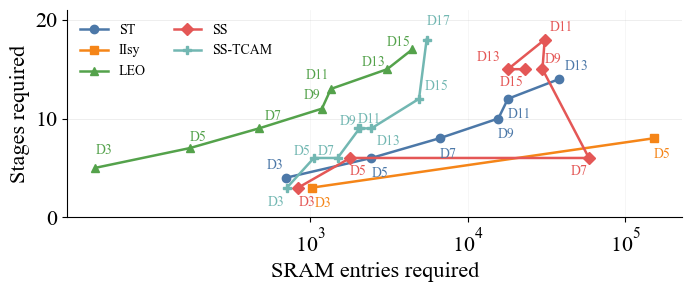

In [13]:
plot_sram(rows, FEATURE_COUNT, STAGE_LIMIT)

### Figure 13(b)

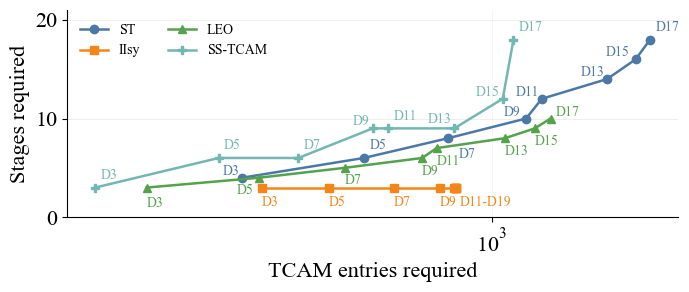

In [14]:
plot_tcam(rows, FEATURE_COUNT, STAGE_LIMIT)